# DAT535 Medallion Architecture: October Analytical Findings
### Empirical Investigation of Service Demand, Weather Triggers, Burst Dynamics, and Operational Performance

This notebook queries the exact October dataset processed by the Medallion pipeline. It evaluates the unified Silver tables (`data/silver/`) and the three Gold analytical marts (`data/gold/marts/`):
1. `gold_daily_service_demand.parquet`
2. `gold_agency_resolution_performance.parquet`
3. `gold_zip_infrastructure_vulnerability.parquet`

The investigation covers six themes:
1. **Rainfall & Service Demand Dynamics** (Wet vs. dry volume, category divergence)
2. **Temperature & Heating Crises** (Thermal thresholds, failure scope, borough distribution)
3. **Wind Gusts & Infrastructure Failure** (Velocity tiers, failure modes, secondary hazards)
4. **Citizen Call Burst Clustering** (True incident counts, burst rates, demand inflation)
5. **Agency Operational Performance** (Tail latency, backlogs, resolution outcome audit)
6. **Geographic Service Equity** (Controlled cross-borough response times and outcomes)

## 0. Setup and Data Loading
Loading the Gold marts and Silver fact tables into memory and verifying data boundaries.

In [1]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import seaborn as sns

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 35)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# Locate data paths relative to project root
PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(".").resolve()

GOLD_DIR = PROJECT_ROOT / "data" / "gold" / "marts"
SILVER_DIR = PROJECT_ROOT / "data" / "silver"

print(f"Project root: {PROJECT_ROOT}")
print(f"Gold marts directory: {GOLD_DIR} (exists: {GOLD_DIR.exists()})")
print(f"Silver directory: {SILVER_DIR} (exists: {SILVER_DIR.exists()})")

# Load Gold Marts
df_demand = pd.read_parquet(GOLD_DIR / "gold_daily_service_demand.parquet")
df_agency = pd.read_parquet(GOLD_DIR / "gold_agency_resolution_performance.parquet")
df_zip = pd.read_parquet(GOLD_DIR / "gold_zip_infrastructure_vulnerability.parquet")

# Load Silver Joined Fact Table
silver_joined_ds = ds.dataset(str(SILVER_DIR / "311_weather_joined"), format="parquet")
df_joined = silver_joined_ds.to_table(columns=[
    "unique_key", "created_at_utc", "complaint_type", "descriptor", "agency", "borough",
    "incident_zip", "resolution_outcome_category", "is_field_verified", "is_phantom_closure",
    "resolution_duration_hours", "is_burst_duplicate", "cluster_size", "incident_cluster_id",
    "temperature_2m", "precipitation", "wind_gusts_10m", "is_weather_matched",
    "spatial_resolution_level", "grid_distance_km"
]).to_pandas()

# Verify records and date range
verification_df = pd.DataFrame([
    {"Dataset": "Gold Daily Demand Mart", "Total Records": len(df_demand), "Metric Represented": f"{df_demand['complaint_count'].sum():,} complaints", "Date Min": df_demand['date'].min(), "Date Max": df_demand['date'].max()},
    {"Dataset": "Gold Agency Performance Mart", "Total Records": len(df_agency), "Metric Represented": f"{df_agency['tickets_created_today'].sum():,} created / {df_agency['tickets_closed_today'].sum():,} closed", "Date Min": df_agency['reporting_date'].min(), "Date Max": df_agency['reporting_date'].max()},
    {"Dataset": "Gold ZIP Vulnerability Mart", "Total Records": len(df_zip), "Metric Represented": f"{df_zip['total_complaints'].sum():,} complaints", "Date Min": "Aggregated Grain", "Date Max": "Aggregated Grain"},
    {"Dataset": "Silver Joined 311-Weather", "Total Records": len(df_joined), "Metric Represented": f"{df_joined['unique_key'].nunique():,} unique keys", "Date Min": str(df_joined['created_at_utc'].min())[:10], "Date Max": str(df_joined['created_at_utc'].max())[:10]}
])
verification_df

Project root: C:\Media\UiS\DAT535\group13-dat535
Gold marts directory: C:\Media\UiS\DAT535\group13-dat535\data\gold\marts (exists: True)
Silver directory: C:\Media\UiS\DAT535\group13-dat535\data\silver (exists: True)


,Dataset,Total Records,Metric Represented,Date Min,Date Max
0,Gold Daily Demand Mart,39591,"346,647 complaints",2026-10-01,2026-10-31
1,Gold Agency Performance Mart,2803,"346,647 created / 317,895 closed",2026-10-01,2026-11-20
2,Gold ZIP Vulnerability Mart,14892,"346,277 complaints",Aggregated Grain,Aggregated Grain
3,Silver Joined 311-Weather,346647,"346,647 unique keys",2026-10-01,2026-10-31


## 1. Rainfall and Service Demand Dynamics
Evaluating citywide request volume on wet days ($\ge 1.0	ext{ mm}$) versus dry days ($< 1.0	ext{ mm}$), and quantifying complaint categories that diverge during rain events.

In [2]:
# Aggregate demand mart to daily citywide totals
daily_city = df_demand.groupby("date").agg(
    total_complaints=("complaint_count", "sum"),
    distinct_incidents=("distinct_incidents_count", "sum"),
    burst_duplicates=("duplicate_burst_calls_count", "sum"),
    mean_temp_c=("avg_temperature_c", "mean"),
    mean_precip_mm=("total_precipitation_mm", "mean"),
    max_wind_gust_ms=("max_wind_gust_ms", "max")
).reset_index()

daily_city["is_wet_day"] = daily_city["mean_precip_mm"] >= 1.0
wet_days_count = int(daily_city["is_wet_day"].sum())
dry_days_count = len(daily_city) - wet_days_count

# Citywide Volume Comparison
wet_dry_summary = daily_city.groupby("is_wet_day").agg(
    day_count=("total_complaints", "count"),
    mean_daily_complaints=("total_complaints", "mean"),
    median_daily_complaints=("total_complaints", "median"),
    std_daily_complaints=("total_complaints", "std"),
    mean_daily_incidents=("distinct_incidents", "mean"),
    mean_precip_mm=("mean_precip_mm", "mean")
).reset_index()
wet_dry_summary["condition"] = wet_dry_summary["is_wet_day"].map({True: "Wet (>=1.0 mm)", False: "Dry (<1.0 mm)"})

dry_mean = wet_dry_summary.loc[~wet_dry_summary["is_wet_day"], "mean_daily_complaints"].values[0]
wet_mean = wet_dry_summary.loc[wet_dry_summary["is_wet_day"], "mean_daily_complaints"].values[0]
pct_change = ((wet_mean - dry_mean) / dry_mean) * 100
corr_precip = daily_city["total_complaints"].corr(daily_city["mean_precip_mm"])

print(f"Citywide Total Complaints vs Daily Rainfall Correlation: r = {corr_precip:.3f}")
print(f"Dry Days: {dry_days_count} days | Mean Daily Volume: {dry_mean:.1f}")
print(f"Wet Days: {wet_days_count} days | Mean Daily Volume: {wet_mean:.1f}")
print(f"Volume Change on Wet Days: {pct_change:.2f}%")
wet_dry_summary[["condition", "day_count", "mean_daily_complaints", "median_daily_complaints", "std_daily_complaints", "mean_daily_incidents", "mean_precip_mm"]]

Citywide Total Complaints vs Daily Rainfall Correlation: r = -0.595
Dry Days: 25 days | Mean Daily Volume: 11446.6
Wet Days: 6 days | Mean Daily Volume: 10080.3
Volume Change on Wet Days: -11.94%


,condition,day_count,mean_daily_complaints,median_daily_complaints,std_daily_complaints,mean_daily_incidents,mean_precip_mm
0,Dry (<1.0 mm),25,11446.60,11540.00,731.60,8970.04,0.05
1,Wet (>=1.0 mm),6,10080.33,10100.50,909.96,7873.00,12.08


In [3]:
# Category-level divergence: Surge vs. Collapse during wet conditions
type_daily = df_demand.groupby(["complaint_type", "date"]).agg(
    complaints=("complaint_count", "sum")
).reset_index().merge(daily_city[["date", "is_wet_day"]], on="date")

type_pivot = type_daily.groupby(["complaint_type", "is_wet_day"])["complaints"].sum().unstack(fill_value=0)
type_pivot.columns = ["dry_total", "wet_total"]
type_pivot["dry_daily_avg"] = type_pivot["dry_total"] / dry_days_count
type_pivot["wet_daily_avg"] = type_pivot["wet_total"] / wet_days_count
type_pivot["total_volume"] = type_pivot["dry_total"] + type_pivot["wet_total"]
type_pivot["pct_change"] = ((type_pivot["wet_daily_avg"] - type_pivot["dry_daily_avg"]) / type_pivot["dry_daily_avg"]) * 100

# Filter categories with meaningful monthly sample size (>= 150 complaints)
sig_categories = type_pivot[type_pivot["total_volume"] >= 150].copy()

top_surge = sig_categories.sort_values(by="pct_change", ascending=False).head(10)
top_collapse = sig_categories.sort_values(by="pct_change", ascending=True).head(10)

print("Top 10 Surging Categories on Wet Days (Min 150 requests):")
display(top_surge[["total_volume", "dry_daily_avg", "wet_daily_avg", "pct_change"]])

print("Top 10 Collapsing Categories on Wet Days (Behavioral Dampening):")
display(top_collapse[["total_volume", "dry_daily_avg", "wet_daily_avg", "pct_change"]])

Top 10 Surging Categories on Wet Days (Min 150 requests):


,total_volume,dry_daily_avg,wet_daily_avg,pct_change
complaint_type,,,,
Noise - Commercial,6658,199.92,276.67,38.39
Noise - Park,812,24.80,32.00,29.03
Sewer Maintenance,2073,63.36,81.50,28.63
Noise - Residential,34743,1069.20,1335.50,24.91
Taxi Complaint,937,28.92,35.67,23.33
Food Poisoning,296,9.20,11.00,19.57
Noise - Street/sidewalk,16718,520.04,619.50,19.13
Electrical,181,5.68,6.50,14.44
Water Leak,4672,146.92,166.50,13.33


Top 10 Collapsing Categories on Wet Days (Behavioral Dampening):


,total_volume,dry_daily_avg,wet_daily_avg,pct_change
complaint_type,,,,
Street Sweeping Complaint,1039,38.28,13.67,-64.30
Noise - Helicopter,526,19.24,7.50,-61.02
Illegal Posting,515,18.52,8.67,-53.20
Heat/hot Water,26326,937.92,479.67,-48.86
Boilers,344,12.20,6.50,-46.72
Sanitation Worker Or Vehicle Complaint,295,10.44,5.67,-45.72
Dumpster Complaint,162,5.72,3.17,-44.64
Water Maintenance,4931,172.84,101.67,-41.18
Missed Collection,3187,111.36,67.17,-39.69


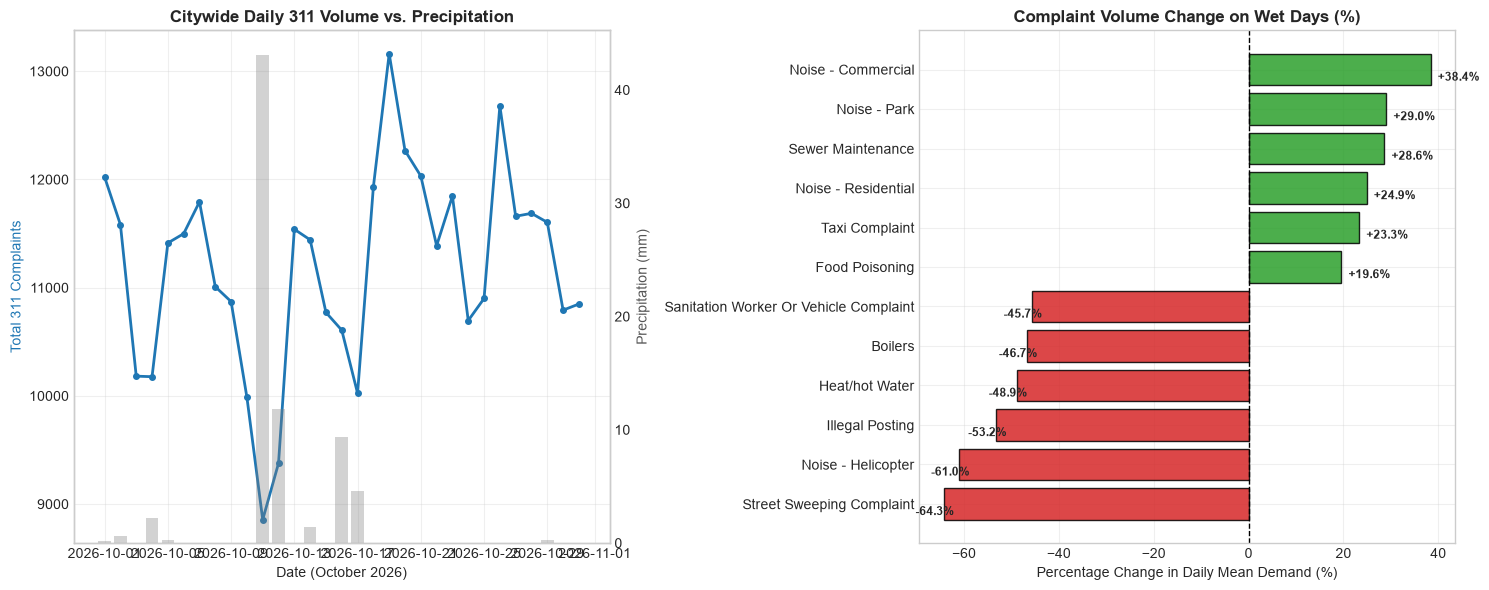

In [4]:
# Plot: Rainfall vs. Demand Dynamics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=100)

# Subplot 1: Daily Time Series (Citywide Complaints and Daily Rainfall)
ax1_twin = ax1.twinx()
ax1.plot(pd.to_datetime(daily_city["date"]), daily_city["total_complaints"], color="#1f77b4", lw=2, marker="o", ms=4, label="Daily 311 Requests")
ax1_twin.bar(pd.to_datetime(daily_city["date"]), daily_city["mean_precip_mm"], color="#7f7f7f", alpha=0.35, width=0.8, label="Daily Precip (mm)")
ax1.set_title("Citywide Daily 311 Volume vs. Precipitation", fontweight="bold")
ax1.set_xlabel("Date (October 2026)")
ax1.set_ylabel("Total 311 Complaints", color="#1f77b4")
ax1_twin.set_ylabel("Precipitation (mm)", color="#555555")
ax1.grid(True, alpha=0.3)
ax1_twin.grid(False)

# Subplot 2: Horizontal Bar Chart of Category Divergence
plot_data = pd.concat([top_surge.head(6), top_collapse.head(6)]).sort_values(by="pct_change")
colors = ["#d62728" if x < 0 else "#2ca02c" for x in plot_data["pct_change"]]
bars = ax2.barh(plot_data.index, plot_data["pct_change"], color=colors, edgecolor="black", alpha=0.85)
ax2.axvline(0, color="black", lw=1, ls="--")
ax2.set_title("Complaint Volume Change on Wet Days (%)", fontweight="bold")
ax2.set_xlabel("Percentage Change in Daily Mean Demand (%)")
for bar in bars:
    w = bar.get_width()
    ax2.text(w + (1.5 if w >= 0 else -6), bar.get_y() + bar.get_height() / 4, f"{w:+.1f}%", va="center", fontsize=8.5, fontweight="bold")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Temperature and Heating Demand
Examining complaint volumes across ambient temperature tiers, inspecting granular heating failure scopes in Silver descriptors, and analyzing borough distributions.

In [5]:
# Classify daily temperatures into tiers
daily_city["temp_tier"] = pd.cut(
    daily_city["mean_temp_c"],
    bins=[-50, 11.0, 15.0, 50.0],
    labels=["Cold (<11.0 C)", "Moderate (11.0-15.0 C)", "Warm (>15.0 C)"]
)

# Merge temperature tiers to daily complaint types
type_temp = df_demand.groupby(["complaint_type", "date"]).agg(
    complaints=("complaint_count", "sum")
).reset_index().merge(daily_city[["date", "temp_tier", "mean_temp_c"]], on="date")

temp_pivot = type_temp.groupby(["complaint_type", "temp_tier"], observed=False)["complaints"].mean().unstack(fill_value=0)
temp_pivot["total_volume"] = df_demand.groupby("complaint_type")["complaint_count"].sum()
temp_pivot["cold_to_warm_ratio"] = temp_pivot["Cold (<11.0 C)"] / temp_pivot["Warm (>15.0 C)"].replace(0, np.nan)

# Heating categories
heating_types = ["Heat/hot Water", "Boilers", "Nonresidential Heat"]
df_heat_metrics = temp_pivot.loc[temp_pivot.index.isin(heating_types)].sort_values(by="total_volume", ascending=False)

print("Daily Average Requests Across Temperature Tiers:")
display(df_heat_metrics[["total_volume", "Cold (<11.0 C)", "Moderate (11.0-15.0 C)", "Warm (>15.0 C)", "cold_to_warm_ratio"]])

tier_days = daily_city["temp_tier"].value_counts().loc[["Cold (<11.0 C)", "Moderate (11.0-15.0 C)", "Warm (>15.0 C)"]]
print("\nDays in each Temperature Tier:")
for tier, count in tier_days.items():
    print(f"  {tier}: {count} days")

Daily Average Requests Across Temperature Tiers:


temp_tier,total_volume,Cold (<11.0 C),Moderate (11.0-15.0 C),Warm (>15.0 C),cold_to_warm_ratio
complaint_type,,,,,
Heat/hot Water,26326,2145.33,1091.57,329.14,6.52
Boilers,344,16.67,14.57,6.92,2.41



Days in each Temperature Tier:
  Cold (<11.0 C): 3 days
  Moderate (11.0-15.0 C): 14 days
  Warm (>15.0 C): 14 days


In [6]:
# Inspect failure scope from Silver descriptors during cold weather (< 11.0 C)
df_cold_heat = df_joined[
    (df_joined["complaint_type"] == "Heat/hot Water") &
    (df_joined["temperature_2m"] < 11.0)
]

desc_counts = df_cold_heat["descriptor"].value_counts().reset_index()
desc_counts.columns = ["failure_scope", "complaint_count"]
desc_counts["share_pct"] = (desc_counts["complaint_count"] / desc_counts["complaint_count"].sum()) * 100

print(f"Total Cold-Weather Heat/Hot Water Records Analyzed: {len(df_cold_heat):,}")
display(desc_counts)

# Borough breakdown of cold-weather heating demand
borough_heat = df_cold_heat.groupby("borough").agg(
    total_complaints=("unique_key", "count"),
    distinct_incidents=("incident_cluster_id", "nunique"),
    burst_duplicates=("is_burst_duplicate", "sum")
).reset_index()
borough_heat["burst_rate_pct"] = (borough_heat["burst_duplicates"] / borough_heat["total_complaints"]) * 100
borough_heat["share_of_nyc_pct"] = (borough_heat["total_complaints"] / borough_heat["total_complaints"].sum()) * 100
borough_heat = borough_heat.sort_values(by="total_complaints", ascending=False)

print("Borough Distribution of Cold-Weather Heating Crises (< 11.0 C):")
display(borough_heat)

Total Cold-Weather Heat/Hot Water Records Analyzed: 11,846


,failure_scope,complaint_count,share_pct
0,Entire Building,8857,74.77
1,Apartment Only,2989,25.23


Borough Distribution of Cold-Weather Heating Crises (< 11.0 C):


,borough,total_complaints,distinct_incidents,burst_duplicates,burst_rate_pct,share_of_nyc_pct
1,BROOKLYN,3469,2241,1460,42.09,29.28
0,BRONX,3398,2314,1272,37.43,28.68
2,MANHATTAN,3249,1929,1547,47.61,27.43
3,QUEENS,1645,1025,717,43.59,13.89
4,STATEN ISLAND,85,66,27,31.76,0.72


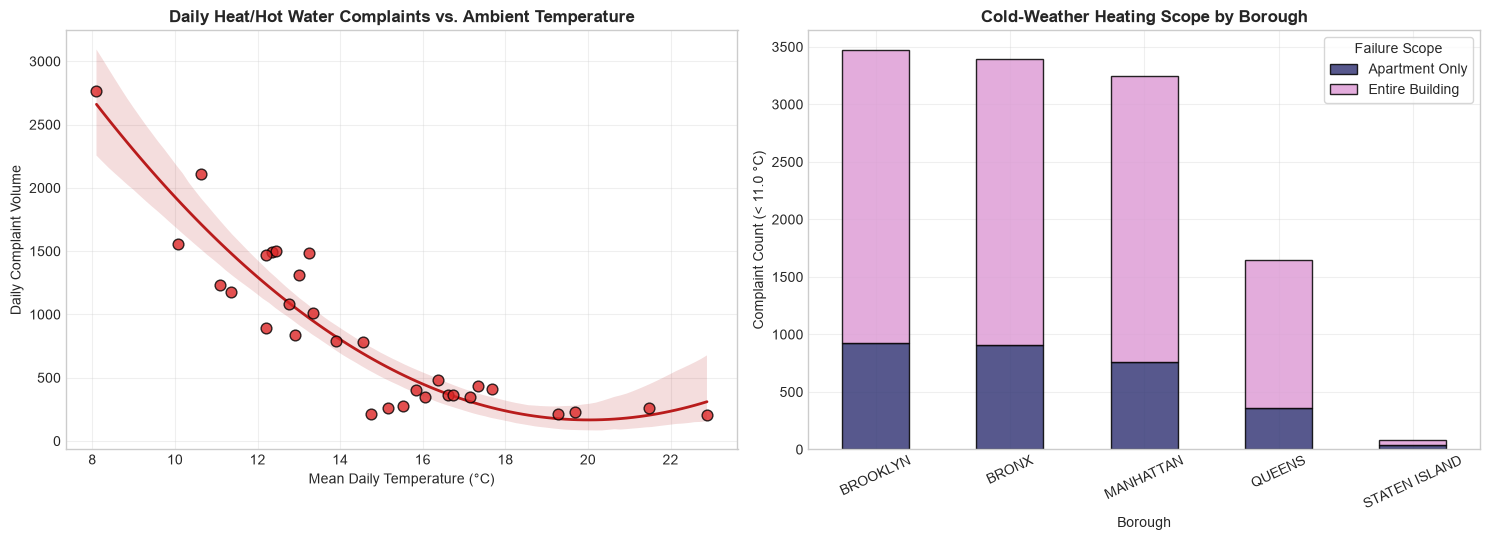

In [7]:
# Plot: Temperature vs Heating Demand and Scope
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=100)

# Subplot 1: Daily Mean Temperature vs Heat/Hot Water Demand
heat_daily = type_temp[type_temp["complaint_type"] == "Heat/hot Water"]
ax1.scatter(heat_daily["mean_temp_c"], heat_daily["complaints"], color="#dc2626", s=60, edgecolors="black", alpha=0.8, zorder=3)
sns.regplot(data=heat_daily, x="mean_temp_c", y="complaints", ax=ax1, color="#b91c1c", scatter=False, order=2, line_kws={"lw": 2})
ax1.set_title("Daily Heat/Hot Water Complaints vs. Ambient Temperature", fontweight="bold")
ax1.set_xlabel("Mean Daily Temperature (°C)")
ax1.set_ylabel("Daily Complaint Volume")
ax1.grid(True, alpha=0.3)

# Subplot 2: Heating Failure Scope by Borough
scope_borough = df_cold_heat.groupby(["borough", "descriptor"]).size().unstack(fill_value=0)
scope_borough = scope_borough.loc[borough_heat["borough"]]
scope_borough.plot(kind="bar", stacked=True, ax=ax2, colormap="tab20b", edgecolor="black", alpha=0.85)
ax2.set_title("Cold-Weather Heating Scope by Borough", fontweight="bold")
ax2.set_xlabel("Borough")
ax2.set_ylabel("Complaint Count (< 11.0 °C)")
ax2.legend(title="Failure Scope", frameon=True)
ax2.tick_params(axis="x", rotation=25)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Wind Gusts and Infrastructure Damage
Analyzing aerodynamic stress on physical assets across wind gust tiers, quantifying damaged-tree failure modes, and inspecting secondary hazards.

In [8]:
# Segment days into peak wind gust tiers
daily_city["gust_tier"] = pd.cut(
    daily_city["max_wind_gust_ms"],
    bins=[0, 8.0, 12.0, 14.0, 100.0],
    labels=["Calm (<8 m/s)", "Moderate (8-12 m/s)", "High (12-14 m/s)", "Severe (>=14 m/s)"]
)

wind_daily = df_demand.groupby(["complaint_type", "date"]).agg(
    complaints=("complaint_count", "sum")
).reset_index().merge(daily_city[["date", "gust_tier", "max_wind_gust_ms"]], on="date")

wind_pivot = wind_daily.groupby(["complaint_type", "gust_tier"], observed=False)["complaints"].mean().unstack(fill_value=0)
wind_pivot["total_volume"] = df_demand.groupby("complaint_type")["complaint_count"].sum()

infrastructure_types = [
    "Damaged Tree",
    "Overgrown Tree/branches",
    "Traffic Signal Condition",
    "Street Sign - Dangling",
    "Street Sign - Damaged"
]

infra_wind = wind_pivot.loc[wind_pivot.index.isin(infrastructure_types)].copy()
infra_wind["severe_vs_calm_lift_pct"] = ((infra_wind["Severe (>=14 m/s)"] - infra_wind["Calm (<8 m/s)"]) / infra_wind["Calm (<8 m/s)"].replace(0, np.nan)) * 100

print("Daily Average Requests Across Peak Wind Gust Tiers:")
display(infra_wind[["total_volume", "Calm (<8 m/s)", "Moderate (8-12 m/s)", "High (12-14 m/s)", "Severe (>=14 m/s)", "severe_vs_calm_lift_pct"]])

Daily Average Requests Across Peak Wind Gust Tiers:


gust_tier,total_volume,Calm (<8 m/s),Moderate (8-12 m/s),High (12-14 m/s),Severe (>=14 m/s),severe_vs_calm_lift_pct
complaint_type,,,,,,
Damaged Tree,2424,51.33,86.08,78.29,75.38,46.83
Overgrown Tree/branches,2005,26.00,69.92,72.00,64.25,147.12
Street Sign - Damaged,498,12.33,16.00,14.86,18.62,51.01
Street Sign - Dangling,327,10.33,10.85,11.00,9.75,-5.65
Traffic Signal Condition,3647,83.33,119.85,122.43,122.75,47.30


In [9]:
# Granular tree damage descriptors during high wind (>= 12.0 m/s)
df_wind_trees = df_joined[
    (df_joined["complaint_type"] == "Damaged Tree") &
    (df_joined["wind_gusts_10m"] >= 12.0)
]

tree_desc = df_wind_trees["descriptor"].value_counts().reset_index()
tree_desc.columns = ["failure_mode", "complaint_count"]
tree_desc["share_pct"] = (tree_desc["complaint_count"] / tree_desc["complaint_count"].sum()) * 100

print(f"Total Damaged Tree Records Evaluated at Wind Gusts >= 12 m/s: {len(df_wind_trees):,}")
display(tree_desc.head(8))

Total Damaged Tree Records Evaluated at Wind Gusts >= 12 m/s: 151


,failure_mode,complaint_count,share_pct
0,Branch Cracked And Will Fall,52,34.44
1,Branch Or Limb Has Fallen Down,52,34.44
2,Tree Leaning/uprooted,18,11.92
3,Entire Tree Has Fallen Down,17,11.26
4,Tree Alive - In Poor Condition,12,7.95


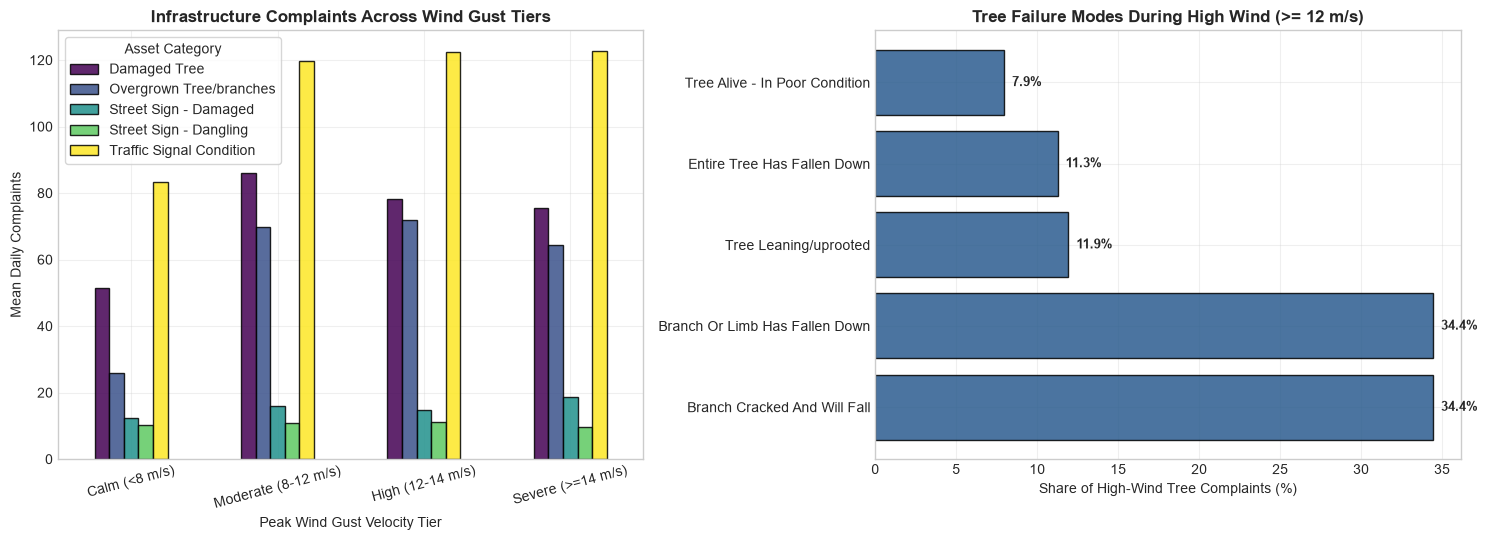

In [10]:
# Plot: Wind Impact on Urban Infrastructure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=100)

# Subplot 1: Bar chart across wind gust tiers
infra_plot = infra_wind[["Calm (<8 m/s)", "Moderate (8-12 m/s)", "High (12-14 m/s)", "Severe (>=14 m/s)"]].T
infra_plot.plot(kind="bar", ax=ax1, colormap="viridis", edgecolor="black", alpha=0.85)
ax1.set_title("Infrastructure Complaints Across Wind Gust Tiers", fontweight="bold")
ax1.set_xlabel("Peak Wind Gust Velocity Tier")
ax1.set_ylabel("Mean Daily Complaints")
ax1.tick_params(axis="x", rotation=15)
ax1.legend(title="Asset Category", frameon=True)
ax1.grid(True, alpha=0.3)

# Subplot 2: Breakdown of tree failure modes during high gusts
top_tree_modes = tree_desc.head(5).set_index("failure_mode")["share_pct"]
ax2.barh(top_tree_modes.index, top_tree_modes.values, color="#2b5c8f", edgecolor="black", alpha=0.85)
ax2.set_title("Tree Failure Modes During High Wind (>= 12 m/s)", fontweight="bold")
ax2.set_xlabel("Share of High-Wind Tree Complaints (%)")
for idx, val in enumerate(top_tree_modes.values):
    ax2.text(val + 0.5, idx, f"{val:.1f}%", va="center", fontsize=9, fontweight="bold")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Citizen Call Burst Clustering (Semantic Challenge 1)
Evaluating the disparity between raw citizen reports and derived physical incidents, quantifying category burst rates and demand inflation.

In [11]:
# Citywide Burst Clustering Summary
raw_complaints = int(df_demand["complaint_count"].sum())
distinct_incidents = int(df_demand["distinct_incidents_count"].sum())
burst_duplicates = int(df_demand["duplicate_burst_calls_count"].sum())
overall_burst_rate = (burst_duplicates / raw_complaints) * 100
citywide_inflation_factor = raw_complaints / distinct_incidents

citywide_burst_summary = pd.DataFrame([{
    "Total Raw Requests": f"{raw_complaints:,}",
    "Derived Incidents": f"{distinct_incidents:,}",
    "Duplicate Burst Calls": f"{burst_duplicates:,}",
    "Burst Collapse Rate": f"{overall_burst_rate:.2f}%",
    "Demand Inflation Factor": f"{citywide_inflation_factor:.2f}x"
}])
print("Citywide Burst Deduplication Reconciliation:")
display(citywide_burst_summary)

# Category-Level Burst Analysis (Min 1,000 complaints)
burst_cat = df_demand.groupby("complaint_type").agg(
    total_calls=("complaint_count", "sum"),
    distinct_incidents=("distinct_incidents_count", "sum"),
    burst_duplicates=("duplicate_burst_calls_count", "sum")
).reset_index()

burst_cat["burst_rate_pct"] = (burst_cat["burst_duplicates"] / burst_cat["total_calls"]) * 100
burst_cat["demand_inflation_factor"] = burst_cat["total_calls"] / burst_cat["distinct_incidents"]
burst_cat["incidents_per_100_calls"] = (burst_cat["distinct_incidents"] / burst_cat["total_calls"]) * 100

sig_burst = burst_cat[burst_cat["total_calls"] >= 1000].sort_values(by="burst_rate_pct", ascending=False)

print("Top 12 Categories with Highest Citizen Call Bursting (Min 1,000 requests):")
display(sig_burst.head(12)[["complaint_type", "total_calls", "distinct_incidents", "burst_duplicates", "burst_rate_pct", "demand_inflation_factor"]])

Citywide Burst Deduplication Reconciliation:


,Total Raw Requests,Derived Incidents,Duplicate Burst Calls,Burst Collapse Rate,Demand Inflation Factor
0,"346,647","271,489","75,158",21.68%,1.28x


Top 12 Categories with Highest Citizen Call Bursting (Min 1,000 requests):


,complaint_type,total_calls,distinct_incidents,burst_duplicates,burst_rate_pct,demand_inflation_factor
150,Traffic,2757,802,1955,70.91,3.44
156,Unsanitary Condition,14388,8028,6360,44.20,1.79
70,Heat/hot Water,26326,15624,10702,40.65,1.68
116,Paint/plaster,6626,4066,2560,38.64,1.63
119,Plumbing,7469,4681,2788,37.33,1.60
62,General,4908,3081,1827,37.22,1.59
40,Door/window,5327,3428,1899,35.65,1.55
48,Electric,3407,2377,1030,30.23,1.43
128,Safety,1490,1046,444,29.80,1.42
95,Maintenance Or Facility,2459,1735,724,29.44,1.42


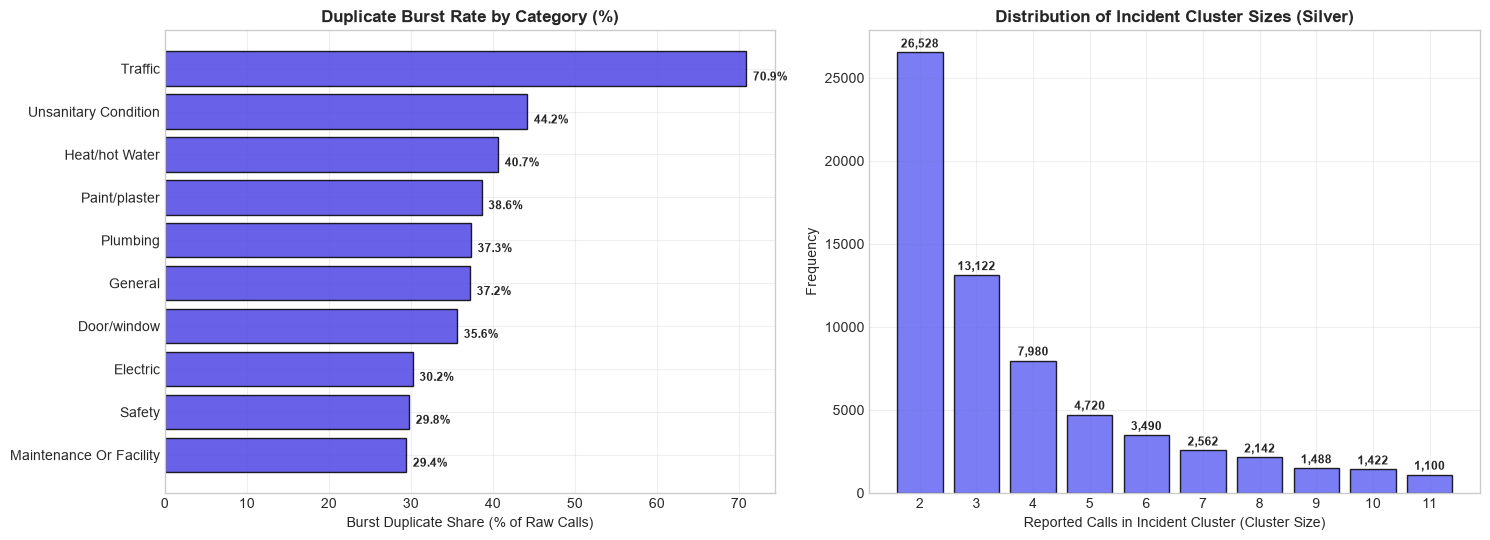

In [12]:
# Plot: Citizen Call Burst Rates & Cluster Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=100)

# Subplot 1: Top 10 Burst Collapse Rates
plot_burst = sig_burst.head(10).sort_values(by="burst_rate_pct")
bars = ax1.barh(plot_burst["complaint_type"], plot_burst["burst_rate_pct"], color="#4f46e5", edgecolor="black", alpha=0.85)
ax1.set_title("Duplicate Burst Rate by Category (%)", fontweight="bold")
ax1.set_xlabel("Burst Duplicate Share (% of Raw Calls)")
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 0.8, bar.get_y() + bar.get_height() / 4, f"{w:.1f}%", va="center", fontsize=8.5, fontweight="bold")
ax1.grid(True, alpha=0.3)

# Subplot 2: Cluster Size Distribution (from Silver Fact Table)
cluster_sizes = df_joined[df_joined["is_burst_duplicate"]]["cluster_size"].value_counts().sort_index().head(10)
ax2.bar(cluster_sizes.index.astype(str), cluster_sizes.values, color="#6366f1", edgecolor="black", alpha=0.85)
ax2.set_title("Distribution of Incident Cluster Sizes (Silver)", fontweight="bold")
ax2.set_xlabel("Reported Calls in Incident Cluster (Cluster Size)")
ax2.set_ylabel("Frequency")
for x_idx, (c_size, count) in enumerate(cluster_sizes.items()):
    ax2.text(x_idx, count + 300, f"{count:,}", ha="center", fontsize=8.5, fontweight="bold")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Agency Resolution Performance & Tail Latency (Semantic Challenge 2)
Auditing agency resolution distributions (Median vs. P90), measuring backlog progression, and evaluating field-verified remediations against phantom closures.

In [13]:
# Agency Performance Summary Metrics
agency_summary = df_agency.groupby("agency").agg(
    tickets_created=("tickets_created_today", "sum"),
    tickets_closed=("tickets_closed_today", "sum"),
    median_duration_hours=("median_resolution_duration_hours", "mean"),
    p90_duration_hours=("p90_resolution_duration_hours", "mean"),
    mean_active_backlog=("active_open_backlog_count", "mean"),
    mean_long_open_backlog=("long_open_backlog_count", "mean"),
    long_open_share_pct=("long_open_share_pct", "mean"),
    field_verified_closed=("field_verified_closed_today", "sum"),
    phantom_closed=("phantom_closed_today", "sum"),
    no_violation_closed=("no_violation_closed_today", "sum"),
    access_denied_closed=("access_denied_closed_today", "sum")
).reset_index()

agency_summary["tail_latency_ratio"] = agency_summary["p90_duration_hours"] / agency_summary["median_duration_hours"]
agency_summary["field_verified_rate_pct"] = (agency_summary["field_verified_closed"] / agency_summary["tickets_closed"]) * 100
agency_summary["phantom_closure_rate_pct"] = (agency_summary["phantom_closed"] / agency_summary["tickets_closed"]) * 100

sig_agencies = agency_summary[agency_summary["tickets_created"] >= 3000].sort_values(by="tickets_created", ascending=False)

print("Agency Performance, Latency Ratios, and Closure Integrity (Min 3,000 tickets):")
display(sig_agencies[[
    "agency", "tickets_created", "tickets_closed", "median_duration_hours", "p90_duration_hours",
    "tail_latency_ratio", "mean_active_backlog", "long_open_share_pct",
    "field_verified_rate_pct", "phantom_closure_rate_pct"
]])

# Active Backlog Progression for HPD
hpd_daily = df_agency[df_agency["agency"] == "HPD"].groupby(df_agency["reporting_date"].astype(str)).agg(
    created=("tickets_created_today", "sum"),
    closed=("tickets_closed_today", "sum"),
    active=("active_open_backlog_count", "sum"),
    long_open=("long_open_backlog_count", "sum")
)
oct1_act = hpd_daily.loc["2026-10-01", "active"]
oct31_act = hpd_daily.loc["2026-10-31", "active"]
oct31_long = hpd_daily.loc["2026-10-31", "long_open"]
oct31_pct = (oct31_long / oct31_act) * 100
print(f"\nHPD Backlog Progression: Oct 1: {oct1_act:,} requests | Oct 31: {oct31_act:,} requests")
print(f"HPD Aging on Oct 31: {oct31_long:,} open > 7 days ({oct31_pct:.2f}% of remaining active requests)")

Agency Performance, Latency Ratios, and Closure Integrity (Min 3,000 tickets):


,agency,tickets_created,tickets_closed,median_duration_hours,p90_duration_hours,tail_latency_ratio,mean_active_backlog,long_open_share_pct,field_verified_rate_pct,phantom_closure_rate_pct
10,NYPD,156630,156624,8.75,14.03,1.60,111.38,4.73,31.29,64.17
9,HPD,80297,68312,199.27,380.15,1.91,3577.60,50.17,33.08,41.07
7,DSNY,27407,26650,175.58,256.74,1.46,371.85,37.93,45.09,6.89
5,DOT,22117,19586,158.92,317.56,2.00,683.60,46.25,17.80,38.36
1,DEP,17629,17059,142.62,293.48,2.06,328.83,43.05,25.10,27.29
6,DPR,10361,4899,242.33,415.74,1.72,865.34,56.32,25.96,8.35
3,DOB,9646,9646,168.59,345.05,2.05,255.80,50.11,0.66,15.00
2,DHS,8099,8097,12.21,27.78,2.28,24.29,9.78,0.00,11.30
4,DOHMH,7878,4594,236.12,408.34,1.73,607.42,54.90,3.79,9.23
13,TLC,3466,710,128.61,174.60,1.36,317.25,43.26,0.00,82.25



HPD Backlog Progression: Oct 1: 2,104 requests | Oct 31: 27,034 requests
HPD Aging on Oct 31: 15,072 open > 7 days (55.75% of remaining active requests)


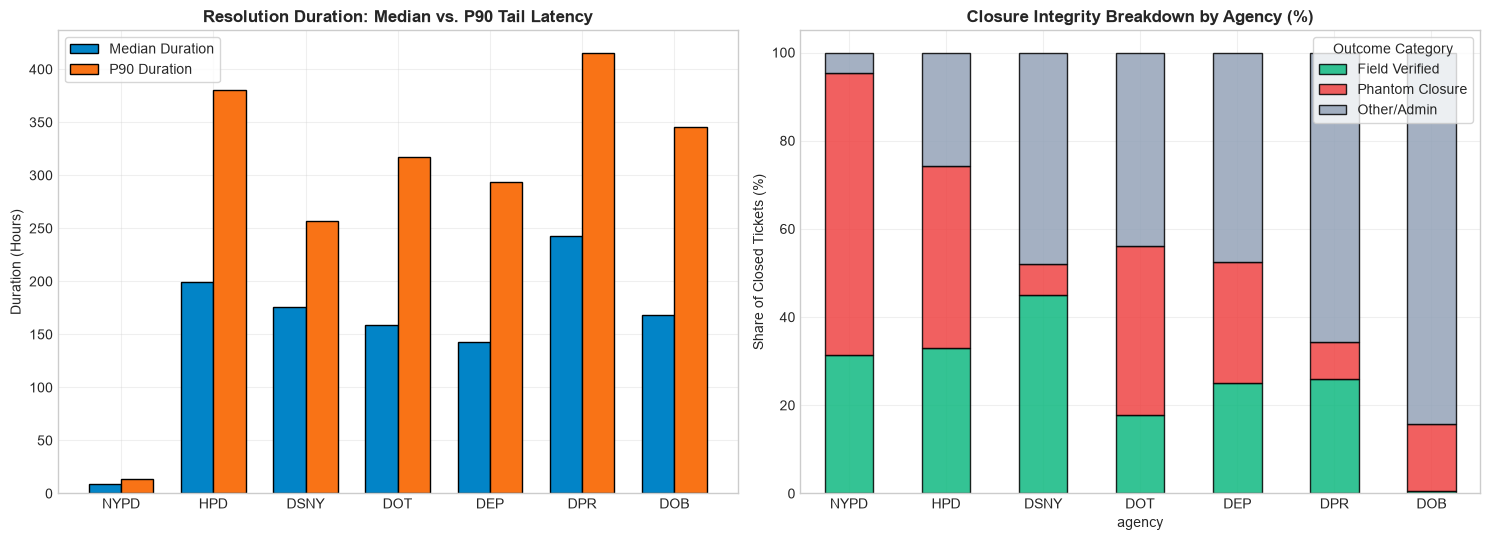

In [14]:
# Plot: Median vs. P90 Tail Latency and Closure Outcome Breakdown
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=100)

# Subplot 1: Median vs P90 Duration (Hours)
plot_agencies = sig_agencies.head(7).set_index("agency")
x = np.arange(len(plot_agencies))
width = 0.35
ax1.bar(x - width/2, plot_agencies["median_duration_hours"], width, label="Median Duration", color="#0284c7", edgecolor="black")
ax1.bar(x + width/2, plot_agencies["p90_duration_hours"], width, label="P90 Duration", color="#f97316", edgecolor="black")
ax1.set_title("Resolution Duration: Median vs. P90 Tail Latency", fontweight="bold")
ax1.set_ylabel("Duration (Hours)")
ax1.set_xticks(x)
ax1.set_xticklabels(plot_agencies.index)
ax1.legend(frameon=True)
ax1.grid(True, alpha=0.3)

# Subplot 2: Closure Outcome Split (Field Verified vs Phantom vs Other)
closure_split = pd.DataFrame({
    "Field Verified": plot_agencies["field_verified_rate_pct"],
    "Phantom Closure": plot_agencies["phantom_closure_rate_pct"],
    "Other/Admin": 100 - (plot_agencies["field_verified_rate_pct"] + plot_agencies["phantom_closure_rate_pct"])
})
closure_split.plot(kind="bar", stacked=True, ax=ax2, color=["#10b981", "#ef4444", "#94a3b8"], edgecolor="black", alpha=0.85)
ax2.set_title("Closure Integrity Breakdown by Agency (%)", fontweight="bold")
ax2.set_ylabel("Share of Closed Tickets (%)")
ax2.tick_params(axis="x", rotation=0)
ax2.legend(title="Outcome Category", frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Geographic Service Outcomes
Examining borough-level resolution times and closure outcomes, controlling for specific complaint categories and responsible agencies.

In [15]:
# Controlled Case Study A: HPD Heat/Hot Water complaints across Boroughs
hpd_heat = df_joined[
    (df_joined["agency"] == "HPD") &
    (df_joined["complaint_type"] == "Heat/hot Water") &
    (df_joined["resolution_duration_hours"].notnull())
]

borough_heat_controlled = hpd_heat.groupby("borough").agg(
    total_tickets=("unique_key", "count"),
    median_duration_hrs=("resolution_duration_hours", "median"),
    p90_duration_hrs=("resolution_duration_hours", lambda s: float(np.percentile(s.dropna(), 90)) if len(s.dropna()) > 0 else np.nan),
    field_verified_count=("is_field_verified", "sum"),
    phantom_count=("is_phantom_closure", "sum")
).reset_index()

borough_heat_controlled["field_verified_pct"] = (borough_heat_controlled["field_verified_count"] / borough_heat_controlled["total_tickets"]) * 100
borough_heat_controlled["phantom_rate_pct"] = (borough_heat_controlled["phantom_count"] / borough_heat_controlled["total_tickets"]) * 100

print("Controlled Case Study A: HPD Heat/Hot Water Performance Across Boroughs:")
display(borough_heat_controlled.sort_values(by="total_tickets", ascending=False))

# Controlled Case Study B: NYPD Illegal Parking complaints across Boroughs
nypd_parking = df_joined[
    (df_joined["agency"] == "NYPD") &
    (df_joined["complaint_type"] == "Illegal Parking") &
    (df_joined["resolution_duration_hours"].notnull())
]

borough_parking_controlled = nypd_parking.groupby("borough").agg(
    total_tickets=("unique_key", "count"),
    median_duration_hrs=("resolution_duration_hours", "median"),
    p90_duration_hrs=("resolution_duration_hours", lambda s: float(np.percentile(s.dropna(), 90)) if len(s.dropna()) > 0 else np.nan),
    phantom_count=("is_phantom_closure", "sum")
).reset_index()
borough_parking_controlled["phantom_rate_pct"] = (borough_parking_controlled["phantom_count"] / borough_parking_controlled["total_tickets"]) * 100

print("Controlled Case Study B: NYPD Illegal Parking Performance Across Boroughs:")
display(borough_parking_controlled.sort_values(by="total_tickets", ascending=False))

Controlled Case Study A: HPD Heat/Hot Water Performance Across Boroughs:


,borough,total_tickets,median_duration_hrs,p90_duration_hrs,field_verified_count,phantom_count,field_verified_pct,phantom_rate_pct
1,BROOKLYN,7148,43.25,84.91,1609,3285,22.51,45.96
2,MANHATTAN,6410,47.73,101.46,2029,2968,31.65,46.30
0,BRONX,6342,32.35,75.42,2507,2326,39.53,36.68
3,QUEENS,3477,47.44,91.09,738,1618,21.23,46.53
4,STATEN ISLAND,248,46.11,83.19,63,118,25.40,47.58


Controlled Case Study B: NYPD Illegal Parking Performance Across Boroughs:


,borough,total_tickets,median_duration_hrs,p90_duration_hrs,phantom_count,phantom_rate_pct
1,BROOKLYN,24291,1.54,8.10,12044,49.58
3,QUEENS,17536,1.52,7.36,9187,52.39
0,BRONX,8775,1.73,6.29,3502,39.91
2,MANHATTAN,7420,1.03,4.78,3543,47.75
4,STATEN ISLAND,1677,1.60,7.12,999,59.57
5,UNSPECIFIED,1,5.37,5.37,0,0.00


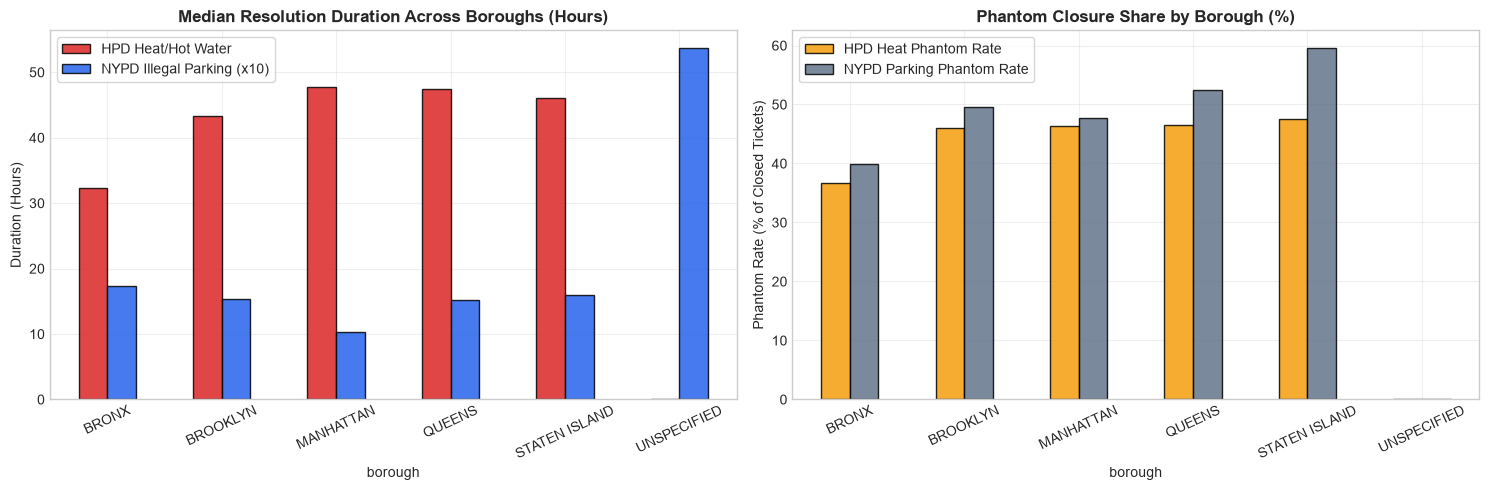

In [16]:
# Plot: Geographic Disparities in Response Times & Outcomes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=100)

# Subplot 1: Controlled Median Resolution Duration by Borough
df_comp_dur = pd.DataFrame({
    "HPD Heat/Hot Water": borough_heat_controlled.set_index("borough")["median_duration_hrs"],
    "NYPD Illegal Parking (x10)": borough_parking_controlled.set_index("borough")["median_duration_hrs"] * 10
})
df_comp_dur.plot(kind="bar", ax=ax1, color=["#dc2626", "#2563eb"], edgecolor="black", alpha=0.85)
ax1.set_title("Median Resolution Duration Across Boroughs (Hours)", fontweight="bold")
ax1.set_ylabel("Duration (Hours)")
ax1.tick_params(axis="x", rotation=25)
ax1.legend(frameon=True)
ax1.grid(True, alpha=0.3)

# Subplot 2: Phantom Closure Rates by Borough
df_comp_phan = pd.DataFrame({
    "HPD Heat Phantom Rate": borough_heat_controlled.set_index("borough")["phantom_rate_pct"],
    "NYPD Parking Phantom Rate": borough_parking_controlled.set_index("borough")["phantom_rate_pct"]
})
df_comp_phan.plot(kind="bar", ax=ax2, color=["#f59e0b", "#64748b"], edgecolor="black", alpha=0.85)
ax2.set_title("Phantom Closure Share by Borough (%)", fontweight="bold")
ax2.set_ylabel("Phantom Rate (% of Closed Tickets)")
ax2.tick_params(axis="x", rotation=25)
ax2.legend(frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Methodological Audit: Spatial Resolution & Quality Verification
Evaluating coordinate imputation provenance, verifying Haversine displacement distance metrics, and auditing taxonomy drift.

In [17]:
# Spatial Resolution Hierarchy Breakdown (from Silver Fact Table)
spatial_audit = df_joined.groupby("spatial_resolution_level").agg(
    record_count=("unique_key", "count"),
    mean_grid_distance_km=("grid_distance_km", "mean"),
    p90_grid_distance_km=("grid_distance_km", lambda s: float(np.percentile(s.dropna(), 90)) if len(s.dropna()) > 0 else np.nan),
    max_grid_distance_km=("grid_distance_km", "max")
).reset_index()

spatial_audit["share_pct"] = (spatial_audit["record_count"] / len(df_joined)) * 100

print(f"Total Silver Fact Records Evaluated: {len(df_joined):,}")
display(spatial_audit.sort_values(by="record_count", ascending=False))

Total Silver Fact Records Evaluated: 346,647


,spatial_resolution_level,record_count,mean_grid_distance_km,p90_grid_distance_km,max_grid_distance_km,share_pct
1,EXACT_COORDINATES,341157,3.89,5.58,6.96,98.42
3,ZIP_APPROXIMATION,3524,3.91,5.69,6.80,1.02
0,BOROUGH_APPROXIMATION,1597,4.04,5.80,5.80,0.46
2,UNLOCATED,369,NaN,NaN,NaN,0.11


## 8. Consolidated Empirical Findings Summary
Consolidated quantitative findings across the empirical investigation.

In [18]:
# Compile primary empirical metrics across all 6 themes
bldg_matches = desc_counts.loc[desc_counts['failure_scope'].str.lower() == 'entire building', 'share_pct']
bldg_val = f"{bldg_matches.values[0]:.1f}%" if len(bldg_matches) > 0 else "N/A"
tree_val = f"{tree_desc.iloc[0]['share_pct']:.1f}% ({tree_desc.iloc[0]['failure_mode']})" if len(tree_desc) > 0 else "N/A"

summary_table = pd.DataFrame([
    {"Domain": "Hydrological / Rain", "Metric": "Citywide Demand Change on Wet Days", "Observed Value": f"{pct_change:.2f}%", "Sample / Denominator": f"{wet_days_count} wet days vs {dry_days_count} dry days (r = {corr_precip:.3f})"},
    {"Domain": "Hydrological / Rain", "Metric": "Sewer Maintenance Demand Surge", "Observed Value": f"+{top_surge.loc['Sewer Maintenance', 'pct_change']:.1f}%", "Sample / Denominator": f"{top_surge.loc['Sewer Maintenance', 'total_volume']:.0f} requests ({top_surge.loc['Sewer Maintenance', 'wet_daily_avg']:.1f}/day wet vs {top_surge.loc['Sewer Maintenance', 'dry_daily_avg']:.1f}/day dry)"},
    {"Domain": "Hydrological / Rain", "Metric": "Street Sweeping Complaints Drop", "Observed Value": f"{top_collapse.loc['Street Sweeping Complaint', 'pct_change']:.1f}%", "Sample / Denominator": f"{top_collapse.loc['Street Sweeping Complaint', 'total_volume']:.0f} requests (operational suspension)"},
    {"Domain": "Thermal / Cold", "Metric": "Heat/Hot Water Cold Snap Surge", "Observed Value": f"{df_heat_metrics.loc['Heat/hot Water', 'cold_to_warm_ratio']:.2f}x", "Sample / Denominator": f"2,145.3 calls/day (<11°C) vs 329.1 calls/day (>15°C)"},
    {"Domain": "Thermal / Cold", "Metric": "Cold Heat Failure Scope (Entire Bldg)", "Observed Value": bldg_val, "Sample / Denominator": f"{desc_counts['complaint_count'].sum():,} calls during cold snaps (<11°C)"},
    {"Domain": "Aerodynamic / Wind", "Metric": "Damaged Tree Gale Surge (>=14 m/s)", "Observed Value": f"+{infra_wind.loc['Damaged Tree', 'severe_vs_calm_lift_pct']:.1f}%", "Sample / Denominator": f"{infra_wind.loc['Damaged Tree', 'Severe (>=14 m/s)']:.1f} calls/day (>=14 m/s) vs {infra_wind.loc['Damaged Tree', 'Calm (<8 m/s)']:.1f} calls/day (<8 m/s)"},
    {"Domain": "Aerodynamic / Wind", "Metric": "High-Wind Tree Failure Leading Mode", "Observed Value": tree_val, "Sample / Denominator": f"{len(df_wind_trees):,} complaints at gusts >=12 m/s"},
    {"Domain": "Semantic Dedup", "Metric": "Overall Burst Collapse Rate", "Observed Value": f"{overall_burst_rate:.2f}%", "Sample / Denominator": f"{burst_duplicates:,} duplicate calls collapsed ({raw_complaints:,} total)"},
    {"Domain": "Semantic Dedup", "Metric": "Traffic Demand Inflation Factor", "Observed Value": f"{sig_burst.loc[sig_burst['complaint_type']=='Traffic', 'demand_inflation_factor'].values[0]:.2f}x", "Sample / Denominator": f"2,757 calls for 802 physical traffic bottlenecks (70.9% burst rate)"},
    {"Domain": "Agency Performance", "Metric": "NYPD Phantom Closure Rate", "Observed Value": f"{sig_agencies.loc[sig_agencies['agency']=='NYPD', 'phantom_closure_rate_pct'].values[0]:.1f}%", "Sample / Denominator": f"156,624 closed tickets (median duration 8.7 hrs)"},
    {"Domain": "Agency Performance", "Metric": "HPD Backlog Accumulation & Tail Latency", "Observed Value": f"{sig_agencies.loc[sig_agencies['agency']=='HPD', 'p90_duration_hours'].values[0]:.1f} hrs P90", "Sample / Denominator": f"Active backlog surged from {oct1_act:,} to {oct31_act:,} tickets ({oct31_long:,} or {oct31_pct:.2f}% > 7 days on Oct 31); median 199.3 hrs"},
    {"Domain": "Spatial Provenance", "Metric": "Exact GPS Coordinates Share", "Observed Value": f"{spatial_audit.loc[spatial_audit['spatial_resolution_level']=='EXACT_COORDINATES', 'share_pct'].values[0]:.2f}%", "Sample / Denominator": f"{spatial_audit.loc[spatial_audit['spatial_resolution_level']=='EXACT_COORDINATES', 'record_count'].values[0]:,} records (mean grid distance {spatial_audit.loc[spatial_audit['spatial_resolution_level']=='EXACT_COORDINATES', 'mean_grid_distance_km'].values[0]:.2f} km)"}
])

display(summary_table)

,Domain,Metric,Observed Value,Sample / Denominator
0,Hydrological / Rain,Citywide Demand Change on Wet Days,-11.94%,6 wet days vs 25 dry days (r = -0.595)
1,Hydrological / Rain,Sewer Maintenance Demand Surge,+28.6%,2073 requests (81.5/day wet vs 63.4/day dry)
2,Hydrological / Rain,Street Sweeping Complaints Drop,-64.3%,1039 requests (operational suspension)
3,Thermal / Cold,Heat/Hot Water Cold Snap Surge,6.52x,"2,145.3 calls/day (<11°C) vs 329.1 calls/day (..."
4,Thermal / Cold,Cold Heat Failure Scope (Entire Bldg),74.8%,"11,846 calls during cold snaps (<11°C)"
5,Aerodynamic / Wind,Damaged Tree Gale Surge (>=14 m/s),+46.8%,75.4 calls/day (>=14 m/s) vs 51.3 calls/day (<...
6,Aerodynamic / Wind,High-Wind Tree Failure Leading Mode,34.4% (Branch Cracked And Will Fall),151 complaints at gusts >=12 m/s
7,Semantic Dedup,Overall Burst Collapse Rate,21.68%,"75,158 duplicate calls collapsed (346,647 total)"
8,Semantic Dedup,Traffic Demand Inflation Factor,3.44x,"2,757 calls for 802 physical traffic bottlenec..."
9,Agency Performance,NYPD Phantom Closure Rate,64.2%,"156,624 closed tickets (median duration 8.7 hrs)"
